# 2. Placing the population in the Galaxy and simulating Gaia's selection

Stages 2 and 3. Both are deliberately simple and built to be swapped out:

| stage | prototype | planned replacement |
| --- | --- | --- |
| Galaxy | uniform cylinder R < 2 kpc around the Sun, age-dependent scale height, a dust slab | Galaxia or FIRE-2 m12i + mwdust |
| Gaia | analytic photocentre signal vs per-transit precision, DR3 cuts | gaiamock epoch astrometry + DR3 cascade (El-Badry et al. 2024) |

`popsynth.gaia.select(mock, release)` is the interface to keep: a gaiamock version only
has to return the same `detected` and `wd_class` columns.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

In [2]:
from popsynth import analysis, galaxy, gaia

## Stage 2: an absolute-number mock of the solar neighbourhood

Each simulated system stands for `weight` real ones, set by the stellar mass formed
per pc² near the Sun (50 Msun/pc², an assumption) over the cylinder's area. Only systems
with 10 < P < 10⁴ d are cloned, since Gaia cannot fit orbits outside that range.

In [3]:
pop = analysis.load_population("fiducial")
mock = galaxy.realise(pop, rng=7)
print(f"each simulated system represents {mock.attrs['weight']:.0f} real ones")
print(f"{len(mock):,} WD+MS systems with 10 < P < 1e4 d within 2 kpc")

each simulated system represents 1557 real ones
1,592,326 WD+MS systems with 10 < P < 1e4 d within 2 kpc


A sanity check on the normalisation: the model has about 1.2 WD + MS binaries per pc²
of disk. The local density of all white dwarfs, 4.5 × 10⁻³ pc⁻³ (Hollands et al. 2018), times a
~300 pc scale height gives about 2.7 per pc². A WD + MS share near 45% is somewhat high, so absolute
counts are uncertain at the factor-of-2 level.

In [4]:
n_all = len(pop) * mock.attrs["weight"]
print(f"WD+MS per pc^2: {n_all / (np.pi * 2000**2):.2f}  (all WDs, rough: {2 * 300 * 4.49e-3:.1f})")

WD+MS per pc^2: 1.19  (all WDs, rough: 2.7)


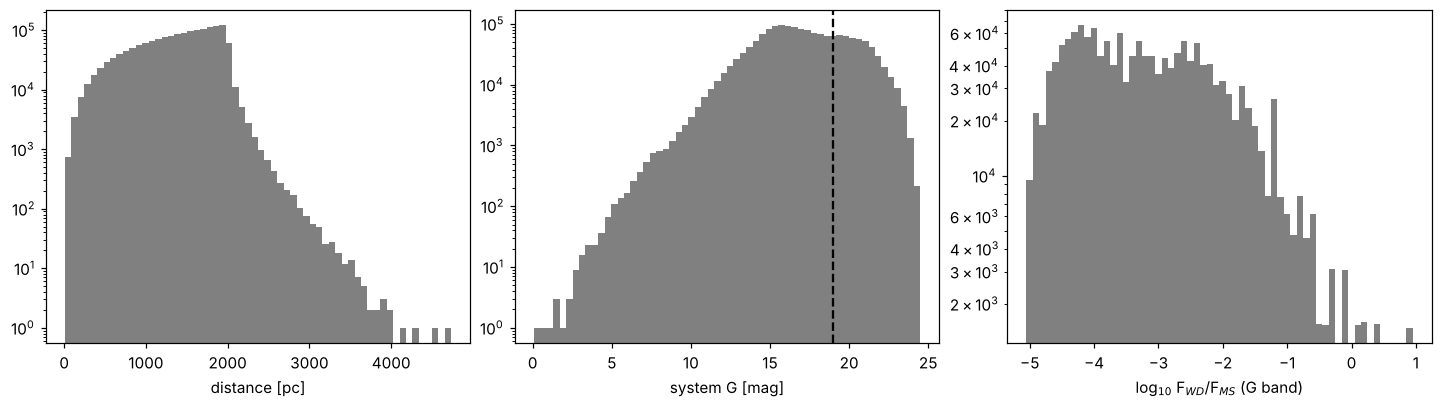

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
axes[0].hist(mock.dist, bins=60, color="0.5"); axes[0].set_xlabel("distance [pc]")
axes[1].hist(mock.G, bins=60, color="0.5"); axes[1].axvline(19, color="k", ls="--"); axes[1].set_xlabel("system G [mag]")
axes[2].hist(np.log10(mock.flux_ratio), bins=60, color="0.5"); axes[2].set_xlabel("log$_{10}$ F$_{WD}$/F$_{MS}$ (G band)")
for ax in axes: ax.set_yscale("log")
plt.show()

The WD is almost always under 1% of the light in G, so the photocentre traces the MS
star and the astrometric signal is close to the full reflex orbit:

a₀ = a_rel × | M_WD / (M_WD + M_MS) − F_WD / (F_WD + F_MS) |

## Stage 3: what Gaia DR3 would accept

The per-transit along-scan precision is a rough fit to the DR3 trend (about 0.1 mas
bright, about 1.6 mas at G = 19). The cuts follow the DR3 orbital solutions (Halbwachs et al. 2023),
simplified. The funnel below applies them one at a time.

In [6]:
dr3 = gaia.GaiaRelease.dr3()
a0 = gaia.photocentre_a0(mock)
sig = gaia.sigma_fov(mock.G.values)
snr = a0 / (sig * np.sqrt(2 / dr3.n_fov))
plx_snr = mock.parallax.values / (1.5 * sig / np.sqrt(dr3.n_fov))
P = mock.porb.values

steps = {
    "all, 10 < P < 1e4 d": np.ones(len(mock), bool),
    "G < 19": mock.G.values < 19,
    "a0 / sigma > 5": snr > 5,
    "a0 / sigma > 158 / sqrt(P)": snr > 158 / np.sqrt(P),
    "parallax / sigma > 20000 / P": plx_snr > 20000 / P,
}
keep = np.ones(len(mock), bool)
rows = []
for name, m in steps.items():
    keep &= m
    rows.append((name, int(keep.sum())))
sel = gaia.select(mock, dr3, rng=8)
rows += [("x period efficiency (random draw)", int(sel.detected.sum())),
         ("dark-companion (AMRF) triage", int(sel.wd_class.sum()))]
pd.DataFrame(rows, columns=["cut (cumulative)", "N systems"])

,cut (cumulative),N systems
0,"all, 10 < P < 1e4 d",1592326
1,G < 19,1146506
2,a0 / sigma > 5,464063
3,a0 / sigma > 158 / sqrt(P),420671
4,parallax / sigma > 20000 / P,292042
5,x period efficiency (random draw),5057
6,dark-companion (AMRF) triage,4373


The period efficiency is a toy stand-in for what gaiamock does properly: orbits become
hard to fit as P approaches the baseline (1038 d for DR3, 2006 d for DR4), and there's a
deficit near 1 yr, where orbit and parallax are degenerate.

**This toy function currently dominates the DR3 count.** In the funnel above it removes about 98% of
systems that pass the signal cuts, because most of them have P > 1000 d (wide binaries that never
interacted). Replacing it with gaiamock is the single most important upgrade before trusting counts.

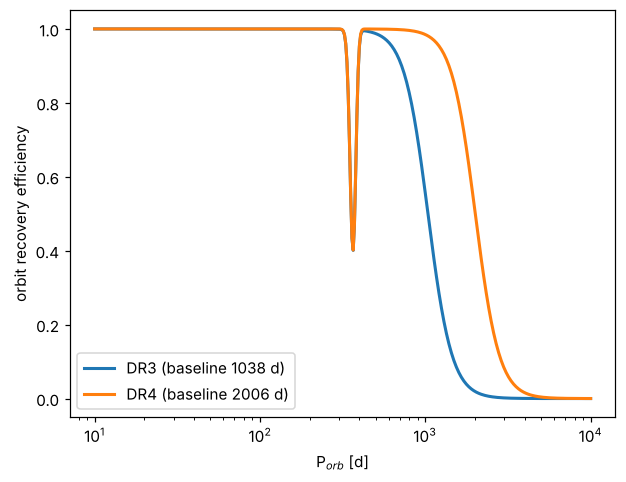

In [7]:
p = np.logspace(1, 4, 400)
for rel in [gaia.GaiaRelease.dr3(), gaia.GaiaRelease.dr4()]:
    plt.plot(p, gaia.period_efficiency(p, rel.baseline_d), lw=2, label=f"{rel.name} (baseline {rel.baseline_d:.0f} d)")
plt.xscale("log"); plt.xlabel("P$_{orb}$ [d]"); plt.ylabel("orbit recovery efficiency"); plt.legend()
plt.show()

## The triage: is the companion too dark to be a star?

Following Shahaf et al. (2019), the astrometric mass-ratio function
A = (a₀/ϖ) / (M₁^(1/3) P_yr^(2/3)) is compared with the largest value any single
main-sequence companion could give. M₁ comes from absolute G with a crude mass-luminosity
relation, applied **identically** to the mock and to real DR3 data (`scripts/fetch_dr3_orbits.py`).
This is looser than the Shahaf class-III cut plus color excess used for the published
sample, which is the main reason absolute counts are not yet comparable.

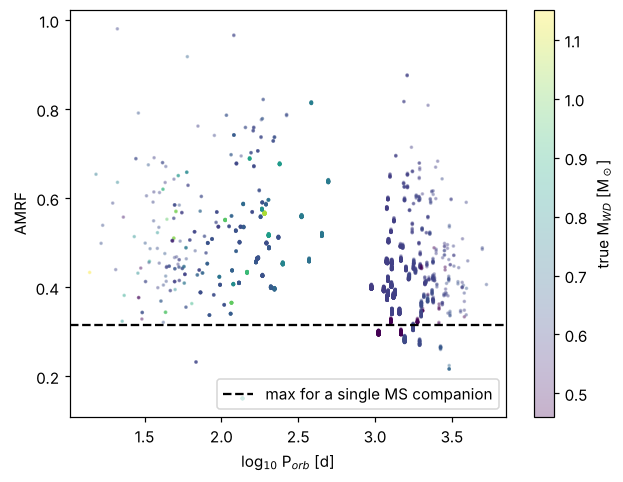

In [8]:
d = sel[sel.detected]
plt.scatter(np.log10(d.porb), d.amrf, s=2, alpha=0.3, c=d.m_wd, cmap="viridis", rasterized=True)
plt.colorbar(label="true M$_{WD}$ [M$_\odot$]")
plt.axhline(gaia.amrf_ms_max(1.0), color="k", ls="--", label="max for a single MS companion")
plt.xlabel("log$_{10}$ P$_{orb}$ [d]"); plt.ylabel("AMRF"); plt.legend(loc="lower right")
plt.show()

Next: [03_compare_dr3_dr4.ipynb](03_compare_dr3_dr4.ipynb).